# Figure 2 — original spatial-omics benchmark

Reproduce the **original nine-dataset, five-method** ARI/NMI/CLC comparison. This is separate from the later NCS six-metric benchmark.

The default run recalculates all three metrics for **all five methods and all seven adjacent pairs of SmallIntestine**, then rebuilds the complete 135-value comparison from the archived per-pair scores. CLC is evaluated both on frozen historical neighbourhood indices and on neighbours freshly selected from coordinates: exact distance ties can select different neighbours across platforms. The final section supports fresh scoring of every dataset. Cached aggregation and freshly executed scoring are explicitly distinguished.

The original plotting code contained two manual overrides and raw/reference normalization with clipping. Those operations appear in a separate historical-display section; they never modify the computed metric table. Python 3.10/3.11, CPU; the small example needs approximately 2 GB RAM.

The accompanying [Linux validation report](../validation/fig2/full_recompute_status.json) records completed fresh recomputation of all **135/135** method means (1,955 adjacent pairs; 5,865 metric scores), matching the original table within 2.23e-16. That archived full validation is distinct from the default execution scope above.

In [1]:
!wget -q -nc https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-scores-20261117.tar.gz
!git clone --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git
!wget -q -nc https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-SmallIntestine-example-20261117.tar.gz
!wget -q -nc https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-SmallIntestine-neighbours-20261117.tar.gz

Cloning into 'omnialigner'...


remote: Enumerating objects: 673, done.
remote: Counting objects: 100% (673/673), done.


remote: Compressing objects: 100% (610/610), done.


fatal: write error: No space left on device
fatal: fetch-pack: invalid index-pack output


In [2]:
!pip -q install numpy==1.26.4 scipy==1.15.3 scikit-learn==1.5.2 pandas==2.2.3 matplotlib==3.9.4 numba==0.61.2

zsh:1: command not found: pip


## 1. Verify and open the scoring inputs

In [1]:
from pathlib import Path
import hashlib, json, tarfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('fig2_data')
OUTPUT = Path('fig2_outputs')
DATA.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)
ASSETS = [{'dataset': 'scores', 'file': 'rev1-fig2-scores-20261117.tar.gz', 'sha256': '2c4c74b128d856c1ddfb2d27b39b1e7c2eb64dd88aced8e31a09acdf7e6bcb22', 'bytes': 96470, 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-scores-20261117.tar.gz'}, {'dataset': 'SmallIntestine', 'file': 'rev1-fig2-SmallIntestine-example-20261117.tar.gz', 'sha256': 'fb4a20c6c97a3d899cc624bfbf651e42435fc050a99241e4e734dae99ca8ffd7', 'bytes': 3663430, 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-SmallIntestine-example-20261117.tar.gz'}, {'dataset': 'SmallIntestine_neighbors', 'file': 'rev1-fig2-SmallIntestine-neighbours-20261117.tar.gz', 'sha256': '6c0ad1f70d8097c6aaa7acf094e8de203bca03b8b17ad60472b30acf9236c7e9', 'bytes': 37566689, 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig2-SmallIntestine-neighbours-20261117.tar.gz'}]
for asset in ASSETS:
    archive = Path(asset['file'])
    assert hashlib.sha256(archive.read_bytes()).hexdigest() == asset['sha256']
    with tarfile.open(archive) as bundle:
        for member in bundle.getmembers():
            assert not member.name.startswith('/') and '..' not in Path(member.name).parts
        bundle.extractall(DATA)

SCORES = DATA / 'fig2_scores'
DATASETS = json.loads((SCORES / 'datasets.json').read_text())
METHODS = ['STalign', 'loki', 'SPACEL', 'spateo', 'omnialigner']
METHOD_LABELS = ['STalign', 'Loki', 'SPACEL', 'Spateo', 'OmniAligner']
METRICS = ['ari', 'nmi', 'CLC']
original_table = pd.read_csv(SCORES / 'original_table.csv')
display(pd.DataFrame([(name, record[0], record[1]) for name, record in DATASETS.items()],
                     columns=['Dataset', 'Original source group', 'Annotation column']))

/var/folders/pn/lrndf8r94g146dh28z3f4bd00000gn/T/ipykernel_98745/413844660.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  bundle.extractall(DATA)


,Dataset,Original source group,Annotation column
0,ABCA1,zhuang/zhuang_ABCA_1,parcellation_structure
1,ABCA2,zhuang/zhuang_ABCA_2,parcellation_structure
2,ABCA3,zhuang/zhuang_ABCA_3,parcellation_structure
3,E9_5,spateo/mouse_E9.5_embryo,mapped_celltype
4,Stereo_embryo,SPACEL/stereo_seq_mouse_embryo,spatial_domain
5,STARmap,SPACEL/starmap_3d_mouse_brain,spatial_domain
6,MLN,openST/metastatic_lymph_node,annotation
7,ST_brain,SPACEL/ST_mouse_brain,spatial_domain
8,SmallIntestine,Loki/SmallIntestine,spatial_domain


## 2. ARI and NMI: categorical raster agreement

Each adjacent pair is evaluated on the saved categorical image grids, **including background pixels**. These two scores use the original scikit-learn definitions. They do not measure molecular prediction or landmark distance.

In [2]:
import numpy as np
from scipy.spatial import KDTree
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from numba import njit


def ari(reference_image, moving_image):
    """Categorical raster ARI, including the background pixels."""
    return float(adjusted_rand_score(reference_image.ravel(), moving_image.ravel()))


def nmi(reference_image, moving_image):
    """Categorical raster NMI, sklearn arithmetic normalization."""
    return float(normalized_mutual_info_score(reference_image.ravel(), moving_image.ravel()))

## 3. CLC: labels and directional neighbourhood preservation

For each source cell, find its nearest target cell. Multiply label agreement by the fraction of the source cell's neighbours whose mapped targets belong to the target cell's neighbourhood; then average over **all source cells**. The neighbourhood contains `max(1, int((n_source+n_target)/2*0.025))` cells, including the cell itself.

The original function was named MNN but fell back to the same directional nearest neighbour whenever a match was not mutual. The implementation below preserves that behavior. Expression features are not used. Batches limit memory without changing the definition.

Frozen neighbour arrays contain **indices, not metric scores**. `clc_from_neighbors` recalculates the complete label/neighbour agreement from them. They fix the historical evaluation support and equal-distance tie choices, while `clc` performs a fresh coordinate-based construction for comparison.

In [3]:
@njit
def _membership_fraction(mapped_neighbors, target_neighbors):
    """Exact set membership using a reusable integer mark array."""
    n, k = mapped_neighbors.shape
    upper = max(np.max(mapped_neighbors), np.max(target_neighbors)) + 1
    marks = np.zeros(upper, dtype=np.int64)
    result = np.zeros(n)
    for row in range(n):
        stamp = row + 1
        for col in range(k):
            marks[target_neighbors[row, col]] = stamp
        count = 0
        for col in range(k):
            if marks[mapped_neighbors[row, col]] == stamp:
                count += 1
        result[row] = count / k
    return result


def clc(labels_reference, labels_moving, coords_reference, coords_moving, batch_size=256):
    """Directional original CLC, computed in bounded-memory blocks.

    Original MNN code keeps a mutual match when present and falls back to the
    source-to-target 1-NN otherwise. Both branches choose the same target index,
    so the final mapping is the single directional nearest-neighbour query.
    Each source point contributes label agreement times the fraction of its
    mapped neighbours belonging to its target point's own neighbourhood.
    Neighbourhoods include the point itself, exactly as in the original code.
    """
    n1, n2 = len(coords_reference), len(coords_moving)
    k = max(1, int((n1 + n2) / 2 * 2.5 / 100))
    if k > min(n1, n2):
        raise ValueError('Historical neighbourhood exceeds one section size.')
    tree1, tree2 = KDTree(coords_reference), KDTree(coords_moving)
    target_index = tree2.query(coords_reference, k=1)[1]
    agreement = labels_reference == labels_moving[target_index]
    contributions = np.zeros(n1, dtype=np.float64)
    active = np.flatnonzero(agreement)
    for start in range(0, len(active), batch_size):
        rows = active[start:start + batch_size]
        source_neighbors = tree1.query(coords_reference[rows], k=k)[1].reshape(len(rows), k)
        target_neighbors = tree2.query(coords_moving[target_index[rows]], k=k)[1].reshape(len(rows), k)
        mapped_neighbors = target_index[source_neighbors]
        contributions[rows] = _membership_fraction(mapped_neighbors, target_neighbors)
    return float(contributions.mean())


def clc_from_neighbors(labels_reference, labels_moving, graph, batch_size=256):
    """Recalculate CLC on frozen evaluation neighbours, including tie choices."""
    target_index = graph['target_index']
    agreement = labels_reference == labels_moving[target_index]
    contributions = np.zeros(len(labels_reference), dtype=np.float64)
    rows_active = np.flatnonzero(agreement)
    target_neighbors = graph['target_neighbors']
    source_neighbors = graph['source_neighbors']
    for start in range(0, len(rows_active), batch_size):
        rows = rows_active[start:start + batch_size]
        mapped_neighbors = target_index[source_neighbors[rows]]
        sorted_neighbors = target_neighbors[target_index[rows]]
        contributions[rows] = _membership_fraction(mapped_neighbors, sorted_neighbors)
    return float(contributions.mean())

## 4. Recalculate one real pair, explicitly

In [4]:
example = np.load(DATA / 'fig2_SmallIntestine' / 'omnialigner.npz', allow_pickle=False)
layers = np.unique(example['layers'])
left = example['layers'] == layers[0]
right = example['layers'] == layers[1]
pair_scores = {}
for metric in [ari, nmi]:
    pair_scores[metric.__name__] = metric(example['raster'][0], example['raster'][1])
pair_scores['CLC'] = clc(example['labels'][left], example['labels'][right],
                         example['coords'][left], example['coords'][right])
display(pd.Series(pair_scores, name='Freshly calculated pair 0'))
example.close()

ari    0.897140
nmi    0.742828
CLC    0.767449
Name: Freshly calculated pair 0, dtype: float64

## 5. Recalculate the complete SmallIntestine comparison

In [5]:
def score_method(npz_path, neighbor_folder=None):
    """Yield one row per adjacent pair; inputs retain original cell ordering."""
    with np.load(npz_path, allow_pickle=False) as data:
        layers = np.unique(data['layers'])
        labels, coords, raster = data['labels'], data['coords'], data['raster']
        if len(layers) != len(raster):
            raise ValueError('Raster/coordinate layer counts differ.')
        for pair, (left, right) in enumerate(zip(layers[:-1], layers[1:])):
            reference, moving = data['layers'] == left, data['layers'] == right
            score = clc(labels[reference], labels[moving], coords[reference], coords[moving])
            result = {'pair': pair,
                      'ari': ari(raster[pair], raster[pair + 1]),
                      'nmi': nmi(raster[pair], raster[pair + 1]),
                      'CLC': score}
            if neighbor_folder is not None:
                with np.load(neighbor_folder / f'{pair}.npz') as graph:
                    result['coordinate_CLC'] = score
                    result['CLC'] = clc_from_neighbors(labels[reference], labels[moving], graph)
            yield result

In [6]:
started = time.time()
fresh_rows = []
for method in METHODS:
    for row in score_method(DATA / 'fig2_SmallIntestine' / f'{method}.npz',
                            DATA / 'fig2_SmallIntestine_neighbors' / method):
        fresh_rows.append({'dataset': 'SmallIntestine', 'method': method, **row})
fresh = pd.DataFrame(fresh_rows)
fresh.to_csv(OUTPUT / 'SmallIntestine_fresh_pair_scores.csv', index=False)
display(fresh.groupby('method')[METRICS].mean().reindex(METHODS))
print(f'Fresh scoring: {len(fresh)} adjacent-pair rows, {time.time()-started:.1f} seconds')

,ari,nmi,CLC
method,,,
STalign,0.847178,0.650964,0.737643
loki,0.851202,0.673657,0.785872
SPACEL,0.810509,0.669885,0.873015
spateo,0.846926,0.676122,0.799372
omnialigner,0.907806,0.766656,0.811258


Fresh scoring: 35 adjacent-pair rows, 11.4 seconds


### Check platform-dependent neighbour choices

This comparison keeps the coordinates and labels fixed. Only the selection among tied neighbours can differ. The frozen-neighbour column is checked strictly against the historical scores; the freshly constructed coordinate graph is reported alongside it, rather than silently changing the tolerance.

In [7]:
tie_check = fresh.groupby('method')[['CLC', 'coordinate_CLC']].mean().reindex(METHODS)
tie_check['coordinate_minus_frozen'] = tie_check['coordinate_CLC'] - tie_check['CLC']
display(tie_check)
tie_check.to_csv(OUTPUT / 'SmallIntestine_coordinate_vs_frozen_neighbors.csv')

,CLC,coordinate_CLC,coordinate_minus_frozen
method,,,
STalign,0.737643,0.737643,0.000000e+00
loki,0.785872,0.785871,-1.093501e-06
SPACEL,0.873015,0.873015,-5.413157e-07
spateo,0.799372,0.799371,-5.456186e-07
omnialigner,0.811258,0.811159,-9.915494e-05


## 6. Rebuild the complete original table from per-pair records

Each dataset/method mean gives equal weight to adjacent pairs. This cell aggregates the archived pair scores for all nine datasets; it does not pretend that the other eight datasets have just been rescored.

In [8]:
archived_rows = []
for dataset in DATASETS:
    for method in METHODS:
        folder = SCORES / dataset / method
        registration = pd.read_csv(folder / 'registration_evaluation.csv')
        labels = pd.read_csv(folder / 'clc_scores.csv')
        for metric in ['ari', 'nmi']:
            values = registration.loc[registration['func'] == metric, 'value']
            archived_rows.append([dataset, method, metric, values.mean()])
        archived_rows.append([dataset, method, 'CLC', labels['CLC_align_spatial_nonrigid'].mean()])
means = pd.DataFrame(archived_rows, columns=['dataset', 'method', 'metric', 'value'])
means['sample'] = means['dataset'].map(lambda name: DATASETS[name][0])
reference = original_table.query("group == 'aligned'").rename(columns={'algo': 'method', 'score': 'reference'})
audit = means.merge(reference[['sample', 'method', 'metric', 'reference']],
                    on=['sample', 'method', 'metric'], validate='one_to_one')
assert len(audit) == 135
np.testing.assert_allclose(audit['value'], audit['reference'], rtol=0, atol=1e-10)

fresh_means = fresh.groupby('method')[METRICS].mean().stack().rename('fresh').reset_index()
fresh_means.columns = ['method', 'metric', 'fresh']
example_check = fresh_means.merge(means.query("dataset == 'SmallIntestine'"), on=['method', 'metric'])
np.testing.assert_allclose(example_check['fresh'], example_check['value'], rtol=0, atol=1e-10)
means.to_csv(OUTPUT / 'Fig2_original_unmodified_metrics.csv', index=False)
display(means.pivot(index=['dataset', 'method'], columns='metric', values='value'))
print('PASS: 135 archived means match the original table; 15 SmallIntestine means freshly reproduced.')

metric                           CLC       ari       nmi
dataset        method                                   
ABCA1          SPACEL       0.669230  0.910842  0.758680
               STalign      0.362348  0.586460  0.487529
               loki         0.645797  0.907526  0.749925
               omnialigner  0.718119  0.936811  0.800362
               spateo       0.648250  0.887903  0.725642
ABCA2          SPACEL       0.569385  0.885681  0.717241
               STalign      0.340550  0.665301  0.536183
               loki         0.527382  0.882307  0.703205
               omnialigner  0.592563  0.909027  0.747134
               spateo       0.547464  0.884876  0.709641
ABCA3          SPACEL       0.575671  0.900922  0.743737
               STalign      0.027550 -0.004604  0.000760
               loki         0.550761  0.917642  0.753102
               omnialigner  0.596117  0.946896  0.790692
               spateo       0.559201  0.919441  0.756872
E9_5           SPACEL       0.238357  0.754730  0.390942
               STalign      0.191788  0.672031  0.323022
               loki         0.212105  0.716772  0.359370
               omnialigner  0.237305  0.765688  0.396987
               spateo       0.216354  0.721137  0.363957
MLN            SPACEL       0.359741  0.772251  0.427694
               STalign      0.137186  0.010553  0.012775
               loki         0.311733  0.783841  0.421745
               omnialigner  0.367917  0.808109  0.456596
               spateo       0.332385  0.771032  0.418729
STARmap        SPACEL       0.844075  0.899707  0.782398
               STalign      0.290066  0.696067  0.425017
               loki         0.472522  0.782894  0.596632
               omnialigner  0.820220  0.941078  0.820647
               spateo       0.831513  0.878878  0.749449
ST_brain       SPACEL       0.695116  0.878956  0.711097
               STalign      0.644945  0.856765  0.673772
               loki         0.645424  0.884571  0.706693
               omnialigner  0.681635  0.904235  0.753142
               spateo       0.689616  0.900600  0.732958
SmallIntestine SPACEL       0.873015  0.810509  0.669885
               STalign      0.737643  0.847178  0.650964
               loki         0.785872  0.851202  0.673657
               omnialigner  0.811258  0.907806  0.766656
               spateo       0.799372  0.846926  0.676122
Stereo_embryo  SPACEL       0.388373  0.825178  0.557695
               STalign      0.250221  0.672142  0.445249
               loki         0.345404  0.858924  0.579126
               omnialigner  0.386514  0.916344  0.638664
               spateo       0.366519  0.871988  0.600477

PASS: 135 archived means match the original table; 15 SmallIntestine means freshly reproduced.


## 7. Reproduce the historical display separately

The archived plotting cell changed the openST reference ARI from its stored value to **0.8**, and changed all three Spateo/E9.5 values to **1.0** before plotting. It then used `(value - raw) / (reference - raw)` and clipped to `[0, 1]`.

These are **historical display overrides**, not metric calculations or new evidence. The table above remains unchanged. The following explicit audit records every modified entry. The original notebook also contained a tenth dataset; this reproduction selects only the nine datasets in the manuscript panel.

,sample,algo,metric,score,historical_display_value
66,spateo/mouse_E9.5_embryo,spateo,nmi,0.363957,1.0
73,spateo/mouse_E9.5_embryo,spateo,ari,0.721137,1.0
80,spateo/mouse_E9.5_embryo,spateo,CLC,0.216354,1.0
96,openST/metastatic_lymph_node,ref,ari,0.743851,0.8


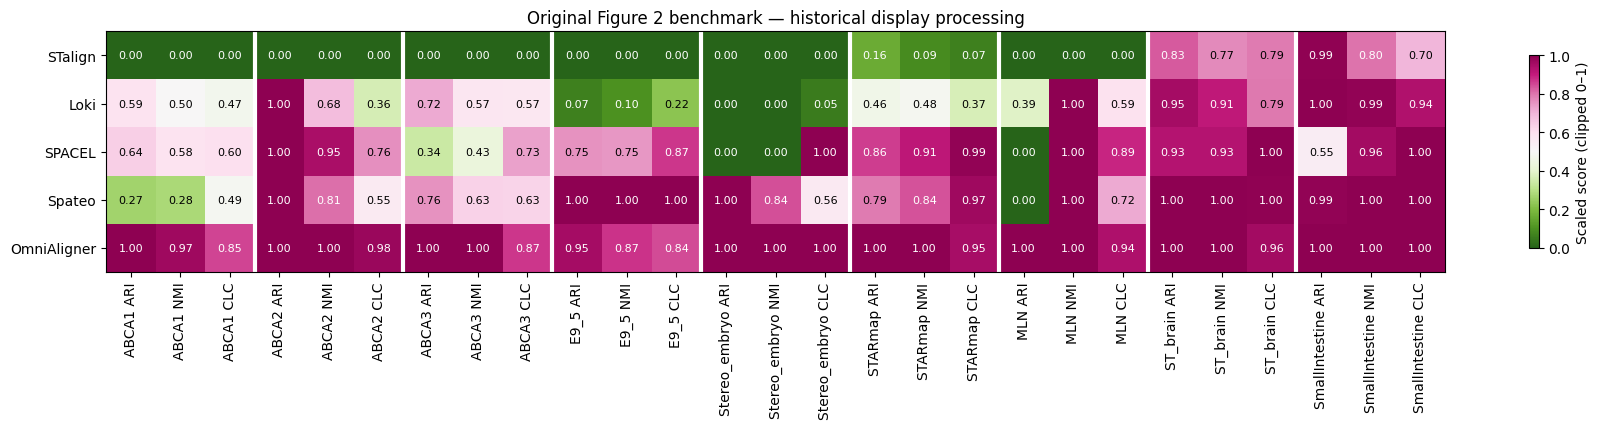

In [9]:
display_table = original_table[original_table['sample'].isin([item[0] for item in DATASETS.values()])].copy()
override_reference = ((display_table['sample'] == 'openST/metastatic_lymph_node') &
                      (display_table['metric'] == 'ari') & (display_table['algo'] == 'ref'))
override_spateo = ((display_table['sample'] == 'spateo/mouse_E9.5_embryo') &
                   (display_table['algo'] == 'spateo'))
overrides = display_table.loc[override_reference | override_spateo].copy()
overrides['historical_display_value'] = np.where(overrides['algo'] == 'ref', 0.8, 1.0)
display(overrides[['sample', 'algo', 'metric', 'score', 'historical_display_value']])
display_table.loc[override_reference, 'score'] = 0.8
display_table.loc[override_spateo, 'score'] = 1.0

columns = [(dataset, metric) for dataset in DATASETS for metric in METRICS]
scaled = np.empty((len(METHODS), len(columns)))
for col, (dataset, metric) in enumerate(columns):
    values = display_table[(display_table['sample'] == DATASETS[dataset][0]) &
                           (display_table['metric'] == metric)].set_index('algo')['score']
    scaled[:, col] = np.clip((values.loc[METHODS] - values['raw']) /
                            (values['ref'] - values['raw']), 0, 1)
pd.DataFrame(scaled, index=METHODS, columns=pd.MultiIndex.from_tuples(columns)).to_csv(
    OUTPUT / 'Fig2_historical_display_values.csv')

fig, ax = plt.subplots(figsize=(18, 4.4))
image = ax.imshow(scaled, vmin=0, vmax=1, cmap='PiYG_r', aspect='auto')
for row in range(len(METHODS)):
    for col in range(len(columns)):
        ax.text(col, row, f'{scaled[row,col]:.2f}', ha='center', va='center', fontsize=8,
                color='black' if 0.2 < scaled[row,col] < 0.8 else 'white')
ax.set_yticks(range(len(METHODS)), METHOD_LABELS)
ax.set_xticks(range(len(columns)), [f'{dataset} {metric.upper()}' for dataset, metric in columns], rotation=90)
for boundary in range(3, len(columns), 3):
    ax.axvline(boundary-0.5, color='white', lw=3)
ax.set_title('Original Figure 2 benchmark — historical display processing')
fig.colorbar(image, ax=ax, label='Scaled score (clipped 0–1)', shrink=0.8)
fig.tight_layout()
fig.savefig(OUTPUT / 'Fig2_benchmark_historical_display.pdf', bbox_inches='tight')
plt.show()

## 8. Full fresh scoring (optional long run)

The complete lossless scoring-input packages are split by dataset. They contain label rasters, labels, layer identities and coordinates, not the full expression H5ADs. Set `RUN_FULL = True` to download all packages and freshly recalculate every adjacent pair. CPU runtime is substantially longer than the small example. Data are processed dataset by dataset; CLC neighbourhoods are queried in bounded-memory batches. The full run constructs neighbours from coordinates, so any platform-dependent tie differences are retained in its difference report.

The asset manifest records SHA-256 hashes and source paths. Raw and reference inputs are included for auditing the historical scaling; the full comparison loop below recalculates the five method rows.

In [10]:
RUN_FULL = False
if RUN_FULL:
    import urllib.request
    manifest = Path('omnialigner/benchmarks/rev1/OmniAligner/src/fig2_assets.json')
    input_assets = json.loads(manifest.read_text())
    full_rows = []
    for asset in input_assets:
        if asset['dataset'] == 'scores':
            continue
        archive = Path(asset['file'])
        if not archive.exists():
            urllib.request.urlretrieve(asset['url'], archive)
        with archive.open('rb') as handle:
            checksum = hashlib.sha256()
            for chunk in iter(lambda: handle.read(8*1024*1024), b''):
                checksum.update(chunk)
        assert checksum.hexdigest() == asset['sha256']
        with tarfile.open(archive) as bundle:
            for member in bundle.getmembers():
                assert not member.name.startswith('/') and '..' not in Path(member.name).parts
            bundle.extractall(DATA)
        dataset = asset['dataset']
        for method in METHODS:
            for row in score_method(DATA / f'fig2_{dataset}' / f'{method}.npz'):
                full_rows.append({'dataset': dataset, 'method': method, **row})
            print(dataset, method, 'complete')
    full = pd.DataFrame(full_rows)
    full.to_csv(OUTPUT / 'Fig2_all_fresh_pair_scores.csv', index=False)
    full_means = full.groupby(['dataset','method'])[METRICS].mean().stack().rename('fresh').reset_index()
    full_means.columns = ['dataset','method','metric','fresh']
    check = full_means.merge(means, on=['dataset','method','metric'], validate='one_to_one')
    assert len(check) == 135
    check['difference'] = check['fresh'] - check['value']
    check.to_csv(OUTPUT / 'Fig2_all_fresh_vs_historical.csv', index=False)
    display(check.pivot_table(index='dataset', columns='metric', values='difference', aggfunc=lambda x: x.abs().max()))
    exact = np.isclose(check['fresh'], check['value'], rtol=0, atol=1e-10)
    print(f'Freshly scored 135 means; {exact.sum()}/135 agree within 1e-10. Inspect any coordinate-neighbour tie differences above.')
else:
    print('Full fresh scoring not requested. This run freshly evaluated SmallIntestine only.')

Full fresh scoring not requested. This run freshly evaluated SmallIntestine only.


## Provenance and limits

Original scoring: `isoST/script/mouse_brain/benchmark.py`; source plotting: `pyvista3d.ipynb`, zero-based cells 32–37 and 42–43. Original source hashes and paths are in the downloaded metadata. Original metric scores, historical plotting overrides and fresh execution scope are reported separately. This notebook reproduces scoring and plotting; it does not refit the five registration algorithms or establish independent anatomical ground truth.